# Functions, Graphs, and Transformations in R

Functions in R allow you to **encapsulate calculations** and reuse them.
Graphs help visualize these functions. Transformations are changes you can make to a function, like scaling, shifting, or reflecting it.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Transformation Rules

Starting from a base function $f(x)$:

| Transformation | Formula | Effect on the graph |
|---|---|---|
| Vertical shift | $f(x) + k$ | up by $k$ (down if $k<0$) |
| Horizontal shift | $f(x - h)$ | **right** by $h$ (counter-intuitive sign!) |
| Vertical scaling | $a \cdot f(x)$ | stretch ($a>1$) or compress ($0<a<1$) |
| Horizontal scaling | $f(bx)$ | compress ($b>1$) or stretch ($0<b<1$) |
| Reflection (x-axis) | $-f(x)$ | flip upside down |
| Reflection (y-axis) | $f(-x)$ | flip left-right |

All of these can be combined: $g(x) = a\,f(x - h) + k$.

In [2]:
# Define a basic function: f(x) = x^2
f <- function(x) x^2

x_vals <- seq(-5, 5, by = 0.1)
y_original    <- f(x_vals)          # original function
y_shift_up    <- f(x_vals) + 5      # vertical shift
y_shift_right <- f(x_vals - 2)      # horizontal shift
y_scaled      <- 2 * f(x_vals)      # vertical scaling
y_reflect     <- -f(x_vals)         # reflection across x-axis

In [3]:
# Print the values at the integer points x = -5, -4, ..., 5
at_int <- x_vals %in% (-5:5)
tab <- data.frame(x = x_vals[at_int],
                  original = y_original[at_int],
                  shift_up = y_shift_up[at_int],
                  shift_right = y_shift_right[at_int],
                  scaled = y_scaled[at_int],
                  reflected = y_reflect[at_int])
print(round(tab, 2), row.names = FALSE)

  x original shift_up shift_right scaled reflected
 -5       25       30          49     50       -25
 -4       16       21          36     32       -16
 -3        9       14          25     18        -9
 -2        4        9          16      8        -4
 -1        1        6           9      2        -1
  0        0        5           4      0         0
  1        1        6           1      2        -1
  2        4        9           0      8        -4
  3        9       14           1     18        -9
  4       16       21           4     32       -16
  5       25       30           9     50       -25


## 2. Visualising Each Transformation

Putting all five curves on one set of axes squeezes them together and clips the reflected curve. Instead we draw **one panel per transformation**, each comparing against the original (dashed), with a fixed y-range so the panels are comparable.

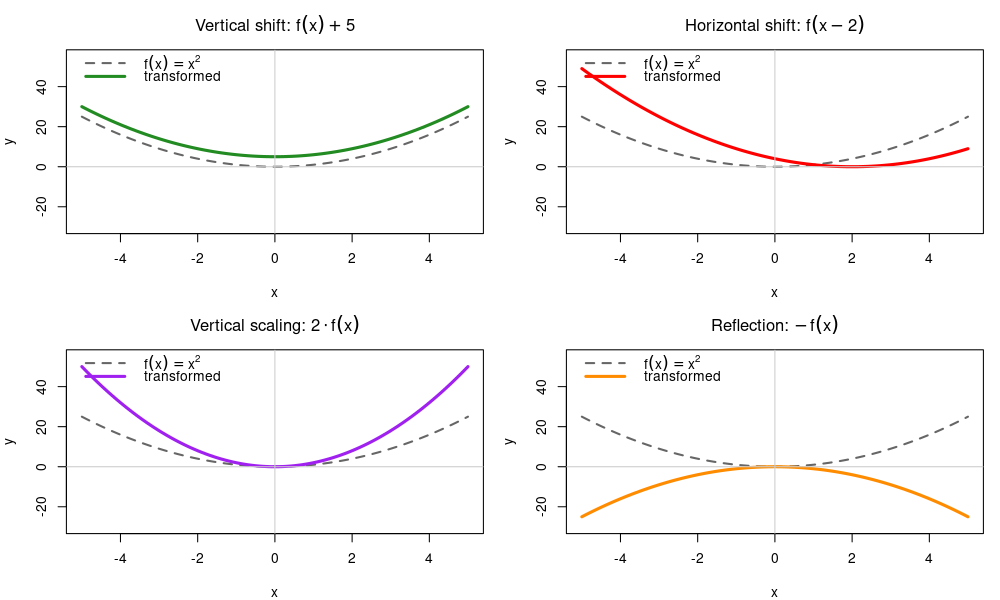

In [4]:
panels <- list(
  list(y = y_shift_up,    col = "forestgreen", title = expression("Vertical shift:" ~ f(x) + 5)),
  list(y = y_shift_right, col = "red",         title = expression("Horizontal shift:" ~ f(x - 2))),
  list(y = y_scaled,      col = "purple",      title = expression("Vertical scaling:" ~ 2 %.% f(x))),
  list(y = y_reflect,     col = "darkorange",  title = expression("Reflection:" ~ -f(x)))
)

par(mfrow = c(2, 2), mar = c(4, 4, 3, 1))
for (p in panels) {
  plot(x_vals, y_original, type = "l", lty = 2, lwd = 2, col = "grey40",
       ylim = c(-30, 55), main = p$title, xlab = "x", ylab = "y")
  lines(x_vals, p$y, lwd = 3, col = p$col)
  abline(h = 0, v = 0, col = "grey80")
  legend("topleft", c(expression(f(x) == x^2), "transformed"),
         col = c("grey40", p$col), lty = c(2, 1), lwd = c(2, 3), bty = "n")
}

*Insight: The horizontal shift $f(x-2)$ moves the parabola to the **right**, even though there is a minus sign. Think of it as "the output that used to happen at $x=0$ now happens at $x=2$".*

## 3. Combining Transformations

A general transformed quadratic is $g(x) = a(x-h)^2 + k$, whose vertex sits at $(h, k)$. Below we write a **function that returns a function** (a *closure*), which is a very R-idiomatic way to build families of curves.

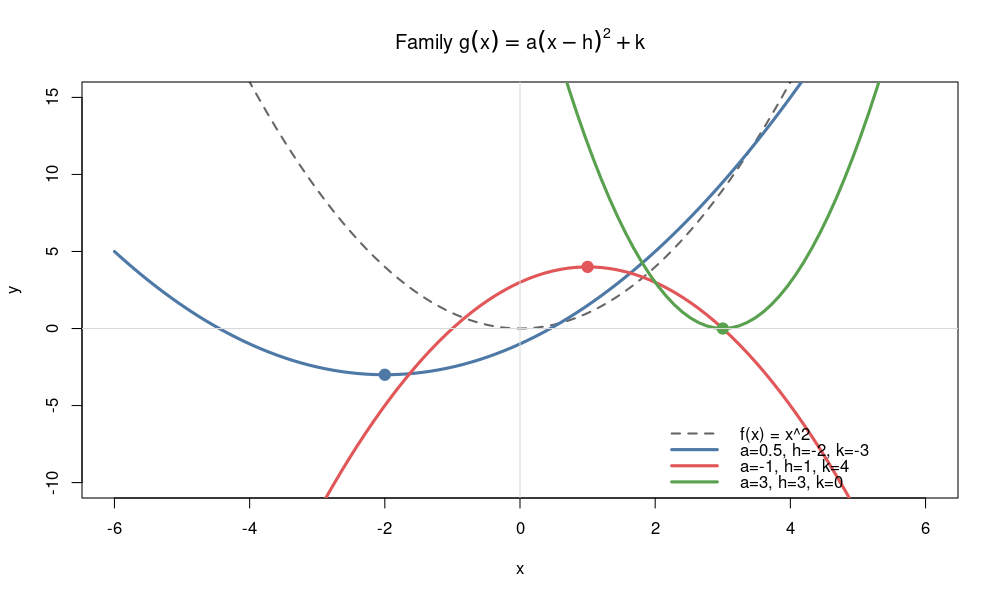

In [5]:
make_transform <- function(f, a = 1, h = 0, k = 0) {
  function(x) a * f(x - h) + k
}

g1 <- make_transform(f, a = 0.5, h = -2, k = -3)
g2 <- make_transform(f, a = -1,  h = 1,  k = 4)
g3 <- make_transform(f, a = 3,   h = 3,  k = 0)

par(mfrow = c(1, 1))
curve(f, -6, 6, lwd = 2, lty = 2, col = "grey40", ylim = c(-10, 15),
      main = expression("Family" ~ g(x) == a(x - h)^2 + k), xlab = "x", ylab = "y")
curve(g1, add = TRUE, lwd = 3, col = "#4E79A7")
curve(g2, add = TRUE, lwd = 3, col = "#E15759")
curve(g3, add = TRUE, lwd = 3, col = "#59A14F")
points(c(-2, 1, 3), c(-3, 4, 0), pch = 19, cex = 1.5, col = c("#4E79A7", "#E15759", "#59A14F"))
abline(h = 0, v = 0, col = "grey85")
legend("bottomright", bty = "n", lwd = c(2, 3, 3, 3), lty = c(2, 1, 1, 1),
       col = c("grey40", "#4E79A7", "#E15759", "#59A14F"),
       legend = c("f(x) = x^2", "a=0.5, h=-2, k=-3", "a=-1, h=1, k=4", "a=3, h=3, k=0"))

## 4. Transformations in Statistics: the Log Transform

Transformations are not just a math-class exercise. Data scientists routinely **transform variables** to make them easier to model. A log transform turns a right-skewed variable (incomes, prices, reaction times) into something much closer to symmetric.

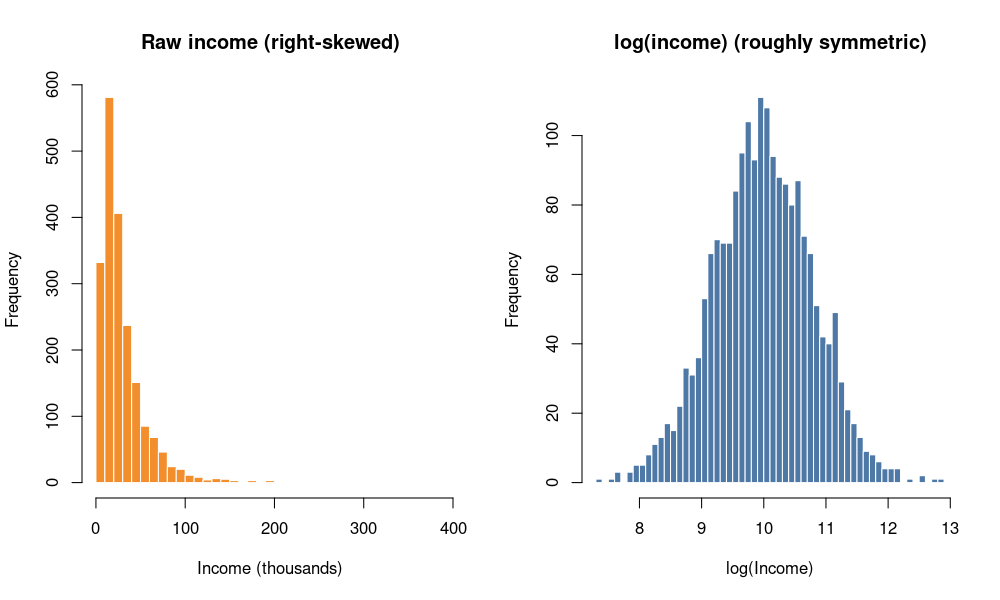

In [6]:
set.seed(42)
income <- rlnorm(2000, meanlog = 10, sdlog = 0.8)

par(mfrow = c(1, 2))
hist(income / 1000, breaks = 40, col = "#F28E2B", border = "white",
     main = "Raw income (right-skewed)", xlab = "Income (thousands)")
hist(log(income), breaks = 40, col = "#4E79A7", border = "white",
     main = "log(income) (roughly symmetric)", xlab = "log(Income)")

*Insight: The log transform compresses large values much more than small ones, pulling in the long right tail. You'll meet it again in regression (Lesson 20) and in GLMs (Lesson 23), where the log is used as a **link function**.*

## Real-World Use Case or Analogy

- Imagine $f(x)$ represents the height of a roller coaster at position $x$.
- **Vertical shifts** lift the entire ride up or down.
- **Horizontal shifts** move the ride along the track.
- **Scaling** makes the hills taller or flatter.
- **Reflection** flips the ride upside down.

The log transform is like switching from a **ruler to a Richter scale**: an earthquake 10x stronger only moves one step on the scale, so huge and tiny events fit on the same chart.